In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing

## Data

In [113]:
data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [114]:
print(data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [116]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [117]:
# Menghitung CV (Coefficient of Variations) -> untuk melihat seberapa besar variasi data berdasarkan standar deviasi terhadap mean

for i in df.columns:
    cv = (df[i].std() / df[i].mean()) * 100
    print(f'CV of {i}:', cv)

CV of MedInc: 49.082490258625874
CV of HouseAge: 43.944774083388324
CV of AveRooms: 45.573277894945974
CV of AveBedrms: 43.213421674197264
CV of Population: 79.44444736711425
CV of AveOccup: 338.23562148606663
CV of Latitude: 5.994501301614503
CV of Longitude: -1.6756181949224374
CV of target: 55.78553100357204


In [118]:
df.duplicated().sum()

0

## Train-Test Split

In [119]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## Data Preparation

In [120]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [121]:
y_train = y_train * 100_000
y_test = y_test * 100_000

In [122]:
y_train

14196    103000.0
8267     382100.0
17445    172600.0
14265     93400.0
2271      96500.0
           ...   
11284    229200.0
11964     97800.0
5390     222100.0
860      283500.0
15795    325000.0
Name: target, Length: 16512, dtype: float64

In [123]:
X_train = X_train.drop(['Latitude', 'Longitude'], axis=1)
X_test = X_test.drop(['Latitude', 'Longitude'], axis=1)

## EDA

### Univariate Analysis

array([[<Axes: title={'center': 'MedInc'}>,
        <Axes: title={'center': 'HouseAge'}>],
       [<Axes: title={'center': 'AveRooms'}>,
        <Axes: title={'center': 'AveBedrms'}>],
       [<Axes: title={'center': 'Population'}>,
        <Axes: title={'center': 'AveOccup'}>]], dtype=object)

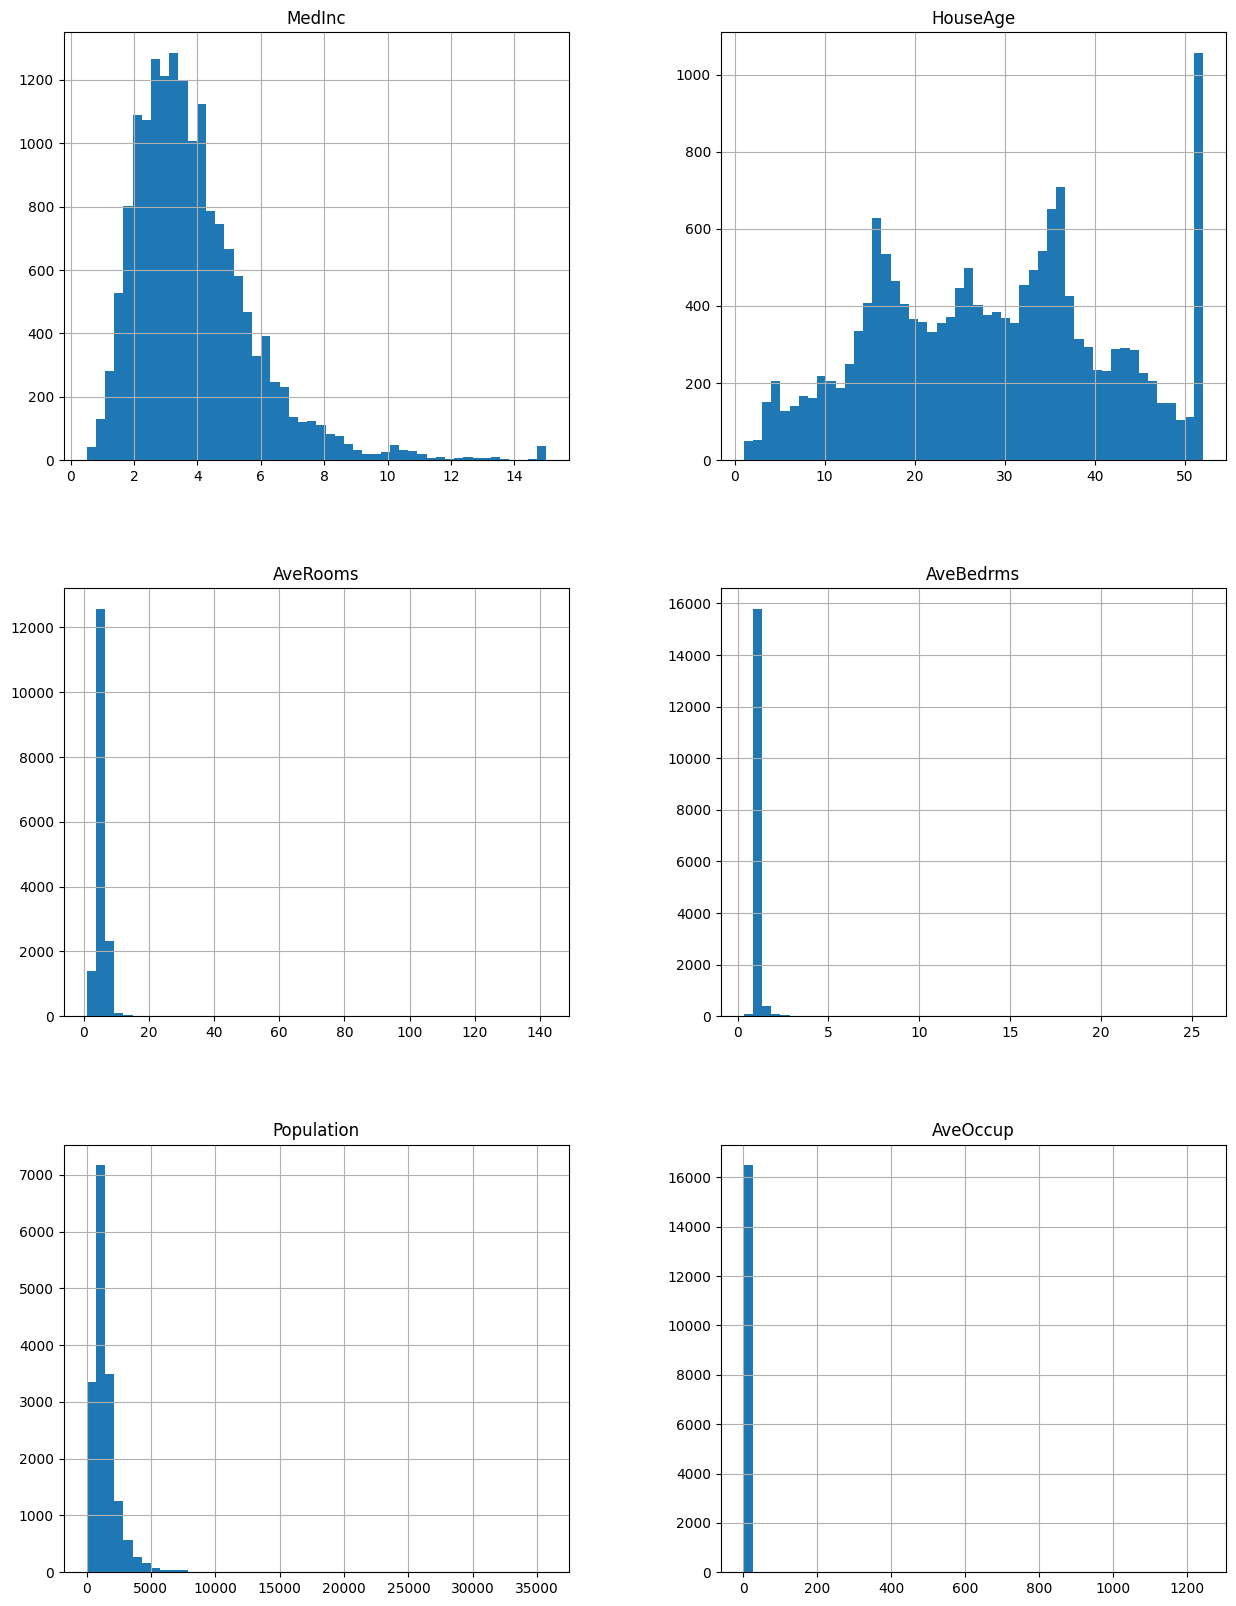

In [124]:
X_train.hist(bins=50, figsize=(15, 20))

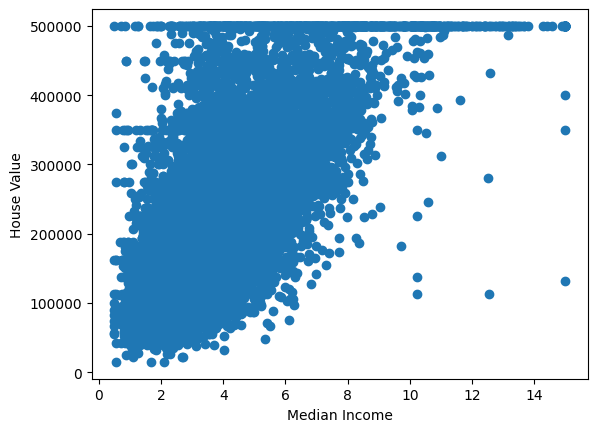

In [125]:
plt.scatter(X_train['MedInc'], y_train)
plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.show()

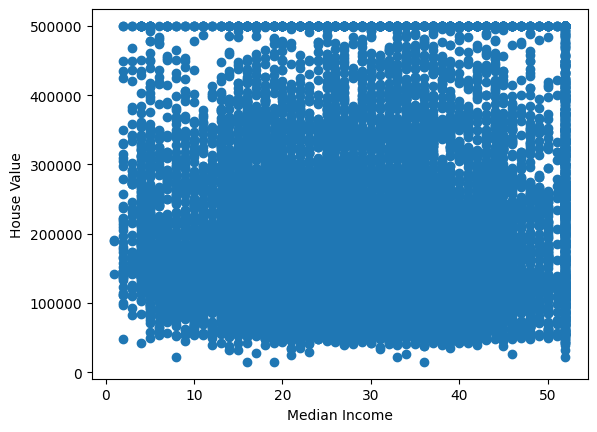

In [126]:
plt.scatter(X_train['HouseAge'], y_train)
plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.show()

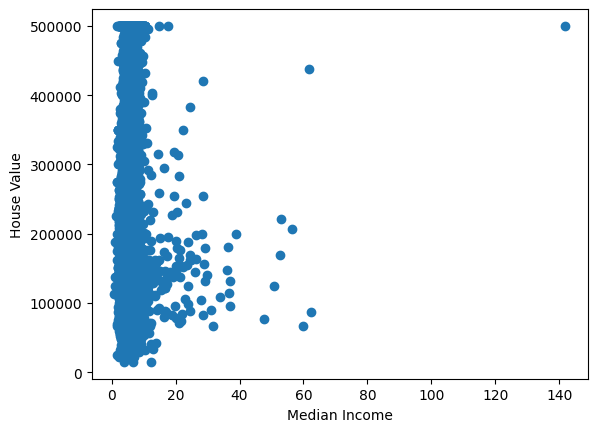

In [127]:
plt.scatter(X_train['AveRooms'], y_train)
plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.show()

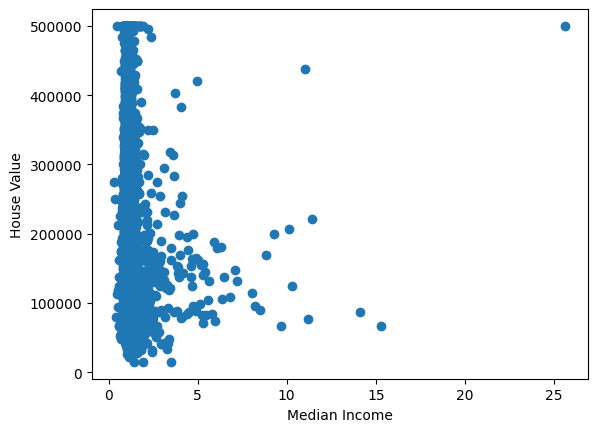

In [128]:
plt.scatter(X_train['AveBedrms'], y_train)
plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.show()

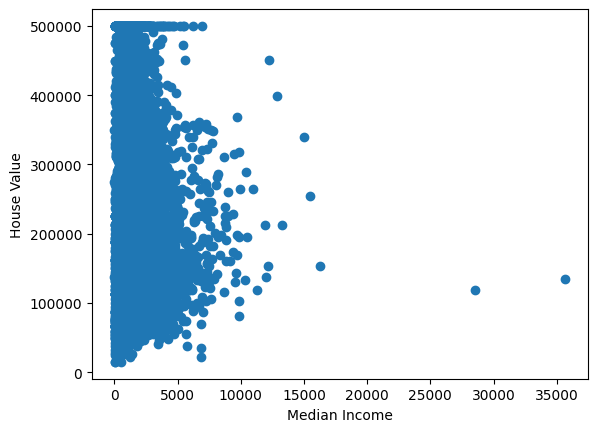

In [129]:
plt.scatter(X_train['Population'], y_train)
plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.show()

### Bivariate

<Axes: >

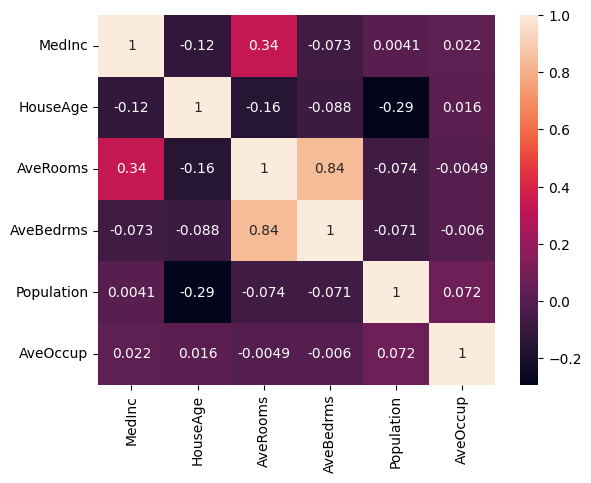

In [130]:
sns.heatmap(X_train.corr(), annot=True)

## Data Cleaning

In [131]:
X_train.isna().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
dtype: int64

In [132]:
X_test.isna().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
dtype: int64

In [133]:
y_train.isna().sum()

0

In [134]:
y_test.isna().sum()

0

In [135]:
# Cek Outlier

results = []

def check_outliers(data):
    results = []

    for col in data.select_dtypes(include='number').columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        count = ((data[col] < lower) | (data[col] > upper)).sum()

        results.append({
            'feature':col,
            'lower_bound': lower,
            'upper_bound': upper,
            'outlier_count': count,
            'outlier_percentage': count /len(data) * 100
        })
    return pd.DataFrame(results)

In [136]:
check_outliers(X_train)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,MedInc,-0.743013,8.082888,529,3.203731
1,HouseAge,-10.500000,65.500000,0,0.000000
2,AveRooms,2.038582,8.474510,410,2.483043
3,AveBedrms,0.865748,1.241107,1153,6.982800
4,Population,-616.500000,3131.500000,955,5.783672
5,AveOccup,1.151997,4.556802,582,3.524709


In [137]:
check_outliers(X_test)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,MedInc,-0.597638,7.792063,152,3.682171
1,HouseAge,-10.500000,65.500000,0,0.000000
2,AveRooms,1.978249,8.427273,100,2.422481
3,AveBedrms,0.866985,1.233262,286,6.928295
4,Population,-630.500000,3133.500000,242,5.862403
5,AveOccup,1.154352,4.570387,133,3.221899


In [138]:
check_outliers(y_train.to_frame())

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,target,-98187.5,483112.5,870,5.268895


In [139]:
check_outliers(y_test.to_frame())

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,target,-96312.5,478587.5,202,4.893411


In [148]:
# Handling outlier dengan dropping


def fit_iqr_bounds(data):
    bounds = {}

    for col in data.select_dtypes(include='number').columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1

        bounds[col] = (
            Q1 - 1.5 * IQR,
            Q3 + 1.5 * IQR
        )
    return bounds

def get_outlier_mask(data, bounds):
    mask = pd.Series(True, index=data.index)

    for col, (lower, upper) in bounds.items():
        if col in data.columns:
            mask &= data[col].between(lower, upper)
    return mask

# 1. Pelajari batas dari X_train -> Jika kamu ingin menangani outlier pada fitur, hitung batas dari X_train.
X_bounds = fit_iqr_bounds(X_train)

# Buat mask berdasarkan batas yang sama
mask_train = get_outlier_mask(X_train, X_bounds)

# Drop baris dari X dan y secara berpasangan
X_train = X_train.loc[mask_train].copy()
y_train = y_train.loc[mask_train].copy()


# 2. Batas target dihitung dari y_train -> Jika kamu ingin menangani outlier pada target, hitung batas dari y_train
y_bounds = fit_iqr_bounds(y_train.to_frame())

mask_y_train = get_outlier_mask(
    y_train.to_frame(), y_bounds
)

X_train = X_train.loc[mask_y_train].copy()
y_train = y_train.loc[mask_y_train].copy()

# train test dan target test, tidak perlu dilakukan drop outlier


In [149]:
check_outliers(X_train)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,MedInc,-0.396925,7.502075,0,0.0
1,HouseAge,-7.000000,65.000000,0,0.0
2,AveRooms,2.381910,7.905135,0,0.0
3,AveBedrms,0.872486,1.217473,0,0.0
4,Population,-344.000000,2736.000000,0,0.0
5,AveOccup,1.244295,4.416294,0,0.0


## Pipeline